# Heart Failure — Random Forest, tratamento dos dados e MLflow

**Objetivo:** repetir, com **Random Forest** (`RandomForestClassifier`), exatamente as estratégias aplicadas à **Árvore de Decisão** na base [Heart Failure Prediction (Kaggle)](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction): tratamento dos dados, ajuste de hiperparâmetros, ablação, engenharia de atributos e avaliação no teste reservado. Todos os experimentos são registrados no **MLflow**, no experimento `heart_failure_random_forest`, para **comparação direta** com o experimento `heart_failure_arvore_decisao`.

**Método (idêntico ao da árvore, para permitir comparação justa)**
- Split treino/teste estratificado (80/20, semente 42). O teste só é usado depois da seleção.
- Zeros fisiologicamente impossíveis (`Cholesterol`, `RestingBP`) viram `NaN` e são imputados **dentro do pipeline** (ajustado apenas no treino de cada fold).
- A grade combina **tratamento dos dados** (estratégia de imputação e codificação categórica) com **hiperparâmetros da floresta** — as mesmas 864 combinações por codificação usadas na árvore, mantendo `n_estimators = 300` fixo na busca.
- Busca com validação cruzada estratificada repetida (5 folds × 2 repetições), refit por **F1 da classe 1**; acurácia, precisão e recall também são medidos na CV.
- O teste é avaliado com acurácia, precisão, recall, F1 (duas classes e macro), IC 95% por bootstrap, matriz de confusão e falsos negativos/positivos.
- Cada configuração é registrada no MLflow (parâmetros, métricas, modelo e artefatos).
- **Ablação:** remoção de um atributo por vez (seleção de features).
- **Engenharia de features:** as mesmas 5 razões/interações clínicas comparadas com e sem.
- **Específico do Random Forest:** *out-of-bag score*, dispersão das importâncias entre as árvores, importância por permutação e **sensibilidade ao número de árvores**.
- **Comparação:** ao final, os resultados da árvore são carregados e tabulados lado a lado com os da floresta.
- Cada execução grava seus resultados em `docs/handle_forest/resultados/execucao_<timestamp>/`.
- Nota: florestas também são **invariantes a transformações monotônicas** das variáveis (os cortes são em limiares), então o `StandardScaler` não altera o resultado — ele é mantido apenas por padronização do pipeline.

In [1]:
import os, json, time, shutil, zipfile, warnings
from datetime import datetime
from pathlib import Path

os.environ['PYTHONWARNINGS'] = 'ignore'   # propaga aos workers do n_jobs=-1
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, GridSearchCV, RepeatedStratifiedKFold,
                                     ParameterGrid, cross_val_score)
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)

import mlflow
import mlflow.sklearn

SEED = 42
N_ARVORES_BUSCA = 300   # n_estimators fixo durante a busca (mesmo orçamento da árvore)
MODELO_JOBS = 1         # o paralelismo fica no GridSearchCV / cross_val_score
print('scikit-learn', sklearn.__version__)
print('mlflow', mlflow.__version__)
print('n_estimators na busca:', N_ARVORES_BUSCA)

scikit-learn 1.9.1
mlflow 3.17.2
n_estimators na busca: 300


In [2]:
def localiza_raiz(inicio=None):
    """Sobe a partir do diretório atual até encontrar a raiz do projeto (bases/heart.csv)."""
    atual = Path(inicio or Path.cwd()).resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / 'bases' / 'heart.csv').exists():
            return pasta
    raise FileNotFoundError('Não encontrei bases/heart.csv a partir de ' + str(atual))

RAIZ = localiza_raiz()
CSV = RAIZ / 'bases' / 'heart.csv'

# tudo que for gerado fica em docs/handle_forest
PASTA_DOCS = RAIZ / 'docs' / 'handle_forest'
PASTA_EXECUCAO = PASTA_DOCS / 'resultados' / f'execucao_{datetime.now():%Y%m%d_%H%M%S}'
PASTA_FIGURAS = PASTA_DOCS / 'figuras'
PASTA_EXECUCAO.mkdir(parents=True, exist_ok=True)
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

# resultados da árvore de decisão (para a comparação final)
PASTA_RESULTADOS_ARVORE = RAIZ / 'resultados'

MLFLOW_DB = (RAIZ / 'mlflow.db').resolve()
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')
EXPERIMENTO = 'heart_failure_random_forest'
EXPERIMENTO_ARVORE = 'heart_failure_arvore_decisao'
mlflow.set_experiment(EXPERIMENTO)


def salva_fig(fig, nome, dpi=150):
    """Salva a figura na pasta da execução e copia para docs/handle_forest/figuras."""
    destino = PASTA_EXECUCAO / nome
    fig.savefig(destino, dpi=dpi, bbox_inches='tight')
    shutil.copy(destino, PASTA_FIGURAS / nome)
    return destino


print('Base:', CSV)
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)
print('Pasta da execução:', PASTA_EXECUCAO)
print('Pasta de figuras:', PASTA_FIGURAS)

2026/10/30 20:51:16 INFO mlflow.tracking.fluent: Experiment with name 'heart_failure_random_forest' does not exist. Creating a new experiment.


Base: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/bases/heart.csv
Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: heart_failure_random_forest
Pasta da execução: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/handle_forest/resultados/execucao_20261030_205115
Pasta de figuras: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/handle_forest/figuras


## Carga e limpeza dos dados

No `heart.csv` original não há `NaN`, mas `Cholesterol` tem muitos zeros (dado faltante codificado como 0) e `RestingBP` tem um. Aqui eles viram `NaN` e são tratados no pipeline — exatamente como no notebook da árvore.

In [3]:
df = pd.read_csv(CSV)
assert 'HeartDisease' in df.columns, 'Coluna HeartDisease não encontrada.'
print('Formato:', df.shape)
display(df.head())
print('Classes:\n', df['HeartDisease'].value_counts().to_string())
print('Valores ausentes (NaN):', int(df.isna().sum().sum()))
print('Linhas duplicadas:', int(df.duplicated().sum()))

# zeros impossíveis -> NaN (regra determinística, sem vazamento; imputação fica no pipeline)
for c in ['Cholesterol', 'RestingBP']:
    if c in df.columns:
        n0 = int((df[c] == 0).sum())
        print(f'{c}: {n0} zeros convertidos em NaN')
        df[c] = df[c].replace(0, np.nan)

print('\nApós a limpeza:')
print(df.isna().sum()[df.isna().sum() > 0].to_string())

Formato: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


Classes:
 HeartDisease
1    508
0    410
Valores ausentes (NaN): 0
Linhas duplicadas: 0
Cholesterol: 172 zeros convertidos em NaN
RestingBP: 1 zeros convertidos em NaN

Após a limpeza:
RestingBP        1
Cholesterol    172


## Preparação dos dados e estratégias de tratamento

O `ColumnTransformer` aplica:
- **Numéricas:** imputação (estratégia escolhida na grade) + padronização;
- **Categóricas:** codificação **one-hot** ou **ordinal** (comparadas na busca).

Tudo é ajustado **somente no treino** de cada fold (dentro do pipeline), sem vazamento. O split e a validação cruzada são idênticos aos da árvore (semente 42), o que garante que as duas abordagens vejam exatamente os mesmos dados de treino e teste.

In [4]:
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']
cat = X.select_dtypes(include=['object', 'category']).columns.tolist()
num = X.select_dtypes(include='number').columns.tolist()
print('Numéricas:', num)
print('Categóricas:', cat)


def make_ohe():
    # compatível com scikit-learn >= 1.2 (sparse_output) e versões anteriores (sparse)
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)


def make_ordinal():
    return OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)


def make_prep_cols(encoding='onehot', scaler='standard', imp_strategy='median',
                   num_cols=None, cat_cols=None):
    num_cols = num if num_cols is None else num_cols
    cat_cols = cat if cat_cols is None else cat_cols
    encoder = make_ohe() if encoding == 'onehot' else make_ordinal()
    sc = StandardScaler() if scaler == 'standard' else 'passthrough'
    transformadores = []
    if num_cols:
        transformadores.append(
            ('num', Pipeline([('imp', SimpleImputer(strategy=imp_strategy)),
                              ('sc', sc)]), num_cols))
    if cat_cols:
        transformadores.append(('cat', encoder, cat_cols))
    return ColumnTransformer(transformadores)


def make_prep(encoding='onehot', scaler='standard'):
    return make_prep_cols(encoding=encoding, scaler=scaler, imp_strategy='median',
                          num_cols=num, cat_cols=cat)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
print('Treino:', len(X_train), '| Teste:', len(X_test))
print('Proporção da classe 1 -> treino: %.3f | teste: %.3f' % (y_train.mean(), y_test.mean()))
print('Classe 0 no teste:', int((y_test == 0).sum()), '| classe 1 no teste:', int((y_test == 1).sum()))

Numéricas: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Categóricas: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Treino: 734 | Teste: 184
Proporção da classe 1 -> treino: 0.553 | teste: 0.554
Classe 0 no teste: 82 | classe 1 no teste: 102


## Busca de hiperparâmetros + tratamento dos dados

A grade é **a mesma da árvore de decisão** (imputação + hiperparâmetros), para que o orçamento de busca seja idêntico: **864 combinações por codificação**, 8.640 ajustes por codificação e **17.280 ajustes** no total. A única diferença é o estimador (`RandomForestClassifier`), com `n_estimators = 300` fixo na busca — o efeito do número de árvores é avaliado separadamente, em uma seção própria.

Para cada codificação (one-hot e ordinal) é executado um `GridSearchCV` com **F1 da classe 1** como métrica de refit; acurácia, precisão e recall também são registradas na validação cruzada. Cada busca vira uma run no MLflow, com o *out-of-bag score* da melhor configuração como métrica adicional.

In [5]:
GRADE = {
    # tratamento dos dados
    'prep__num__imp__strategy': ['median', 'mean', 'most_frequent'],
    # hiperparâmetros da floresta (mesma grade da árvore)
    'modelo__criterion': ['gini', 'entropy'],
    'modelo__max_depth': [3, 5, 7, None],
    'modelo__min_samples_split': [2, 5, 10],
    'modelo__min_samples_leaf': [1, 3, 5],
    'modelo__max_features': [None, 'sqrt'],
    'modelo__class_weight': [None, 'balanced'],
}
SCORING = {'f1': 'f1', 'acuracia': 'accuracy', 'precisao': 'precision', 'recall': 'recall'}

ENCODINGS = ['onehot', 'ordinal']
N_COMBINACOES = len(ParameterGrid(GRADE))
resultados = {}

for enc in ENCODINGS:
    print(f'\n=== Codificação: {enc} ===')
    pipe = Pipeline([
        ('prep', make_prep(enc)),
        ('modelo', RandomForestClassifier(n_estimators=N_ARVORES_BUSCA,
                                          random_state=SEED, n_jobs=MODELO_JOBS)),
    ])
    busca = GridSearchCV(pipe, GRADE, cv=cv, scoring=SCORING, refit='f1',
                         n_jobs=-1, return_train_score=True, error_score='raise')
    with mlflow.start_run(run_name=f'random_forest_{enc}') as run:
        inicio = time.time()
        busca.fit(X_train, y_train)
        duracao = time.time() - inicio
        i = busca.best_index_
        mlflow.log_param('encoding', enc)
        mlflow.log_param('n_combinacoes', N_COMBINACOES)
        mlflow.log_param('n_estimators', N_ARVORES_BUSCA)
        mlflow.log_param('n_fits', N_COMBINACOES * cv.get_n_splits())
        mlflow.log_param('cv', 'RepeatedStratifiedKFold(5x2)')
        mlflow.log_params({k: str(v) for k, v in busca.best_params_.items()})
        mlflow.log_metric('tempo_busca_s', float(duracao))
        mlflow.log_metric('f1_cv', busca.best_score_)
        mlflow.log_metric('f1_cv_std', busca.cv_results_['std_test_f1'][i])
        mlflow.log_metric('f1_treino_cv', busca.cv_results_['mean_train_f1'][i])
        mlflow.log_metric('acuracia_cv', busca.cv_results_['mean_test_acuracia'][i])
        mlflow.log_metric('precisao_cv', busca.cv_results_['mean_test_precisao'][i])
        mlflow.log_metric('recall_cv', busca.cv_results_['mean_test_recall'][i])

        # out-of-bag score da melhor configuração (recurso exclusivo de ensembles por bootstrap)
        oob = float('nan')
        try:
            pipe_oob = clone(busca.best_estimator_).set_params(modelo__oob_score=True)
            pipe_oob.fit(X_train, y_train)
            oob = float(pipe_oob.named_steps['modelo'].oob_score_)
            mlflow.log_metric('oob_score', oob)
        except Exception as erro:
            print('OOB não calculado:', erro)

        cv_path = PASTA_EXECUCAO / f'variacoes_random_forest_{enc}.csv'
        pd.DataFrame(busca.cv_results_).to_csv(cv_path, index=False)
        mlflow.log_artifact(str(cv_path))
        mlflow.sklearn.log_model(
            busca.best_estimator_, name='modelo',
            skops_trusted_types=['numpy.dtype', 'sklearn.tree._tree.Tree'])

        resultados[enc] = {'busca': busca, 'run_id': run.info.run_id,
                           'oob': oob, 'duracao': duracao}

    print('Combinações:', N_COMBINACOES,
          '| fits:', N_COMBINACOES * cv.get_n_splits(),
          '| tempo: %.1f s' % duracao)
    print('Melhor F1 (validação): %.4f ± %.4f' % (
        busca.best_score_, busca.cv_results_['std_test_f1'][i]))
    print('Acurácia (validação): %.4f | Precisão: %.4f | Recall: %.4f' % (
        busca.cv_results_['mean_test_acuracia'][i],
        busca.cv_results_['mean_test_precisao'][i],
        busca.cv_results_['mean_test_recall'][i]))
    print('F1 no treino da CV:    %.4f' % busca.cv_results_['mean_train_f1'][i])
    print('OOB score:             %.4f' % oob)
    print('Melhores parâmetros:', busca.best_params_)


=== Codificação: onehot ===


Combinações: 864 | fits: 8640 | tempo: 722.0 s
Melhor F1 (validação): 0.8809 ± 0.0291
Acurácia (validação): 0.8658 | Precisão: 0.8722 | Recall: 0.8917
F1 no treino da CV:    0.9145
OOB score:             0.8583
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': None, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 2, 'prep__num__imp__strategy': 'median'}

=== Codificação: ordinal ===


Combinações: 864 | fits: 8640 | tempo: 865.3 s
Melhor F1 (validação): 0.8799 ± 0.0280
Acurácia (validação): 0.8658 | Precisão: 0.8792 | Recall: 0.8830
F1 no treino da CV:    0.9524
OOB score:             0.8583
Melhores parâmetros: {'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': 7, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 5, 'prep__num__imp__strategy': 'mean'}


In [6]:
for enc, item in resultados.items():
    r = pd.DataFrame(item['busca'].cv_results_)
    col_rank = 'rank_test_f1' if 'rank_test_f1' in r.columns else 'rank_test_score'
    r = r.sort_values(col_rank).head(5)
    print(f'\nTop 5 — codificação {enc}')
    display(r[['params', 'mean_test_f1', 'std_test_f1',
               'mean_test_acuracia', 'mean_test_precisao',
               'mean_train_f1']].round(4))


Top 5 — codificação onehot


,params,mean_test_f1,std_test_f1,mean_test_acuracia,mean_test_precisao,mean_train_f1
861,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8809,0.0291,0.8658,0.8722,0.9145
858,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8809,0.0291,0.8658,0.8722,0.9145
855,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8809,0.0291,0.8658,0.8722,0.9145
405,"{'modelo__class_weight': None, 'modelo__criter...",0.8804,0.0318,0.8637,0.8610,1.0000
845,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8801,0.0288,0.8651,0.8723,0.9408



Top 5 — codificação ordinal


,params,mean_test_f1,std_test_f1,mean_test_acuracia,mean_test_precisao,mean_train_f1
787,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8799,0.0280,0.8658,0.8792,0.9524
142,"{'modelo__class_weight': None, 'modelo__criter...",0.8789,0.0283,0.8617,0.8578,0.9409
359,"{'modelo__class_weight': None, 'modelo__criter...",0.8782,0.0304,0.8610,0.8581,0.9420
412,"{'modelo__class_weight': None, 'modelo__criter...",0.8782,0.0302,0.8610,0.8588,0.9528
574,"{'modelo__class_weight': 'balanced', 'modelo__...",0.8779,0.0266,0.8631,0.8737,0.9379


## Avaliação no teste reservado

As métricas de teste são calculadas apenas depois da seleção e registradas nas mesmas runs do MLflow, junto com a matriz de confusão e as importâncias das variáveis. As métricas são reportadas para **as duas classes** (0 = sem doença, 1 = com doença) e para a média macro. Os **falsos negativos da classe 1** (paciente doente previsto como sadio) são contabilizados explicitamente, pois são o erro de maior gravidade clínica.

In [7]:
def bootstrap_f1(y_true, pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        vals.append(f1_score(y_true[idx], pred[idx], zero_division=0))
    return np.percentile(vals, [2.5, 97.5])


def nomes_features(prep):
    return list(prep.get_feature_names_out())


def metricas_teste(y_true, pred):
    """Métricas das duas classes, matriz de confusão e IC 95% do F1 da classe 1."""
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    lo, hi = bootstrap_f1(y_true, pred)
    return {
        'Acuracia': float(accuracy_score(y_true, pred)),
        'Precisao_c0': float(precision_score(y_true, pred, pos_label=0, zero_division=0)),
        'Recall_c0': float(recall_score(y_true, pred, pos_label=0, zero_division=0)),
        'F1_c0': float(f1_score(y_true, pred, pos_label=0, zero_division=0)),
        'Precisao_c1': float(precision_score(y_true, pred, pos_label=1, zero_division=0)),
        'Recall_c1': float(recall_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1_c1': float(f1_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1_macro': float(f1_score(y_true, pred, average='macro', zero_division=0)),
        'F1_c1_IC95_inf': float(lo),
        'F1_c1_IC95_sup': float(hi),
        'TN': float(tn), 'FP': float(fp), 'FN': float(fn), 'TP': float(tp),
    }


linhas = []
importancias = {}

for enc, item in resultados.items():
    busca = item['busca']
    pred = busca.predict(X_test)
    metricas = metricas_teste(y_test, pred)
    i = busca.best_index_
    linhas.append({
        'Encoding': enc,
        'F1_CV': float(busca.best_score_),
        'Acuracia_CV': float(busca.cv_results_['mean_test_acuracia'][i]),
        'Precisao_CV': float(busca.cv_results_['mean_test_precisao'][i]),
        'Recall_CV': float(busca.cv_results_['mean_test_recall'][i]),
        'OOB': item['oob'],
        'Tempo_busca_s': item['duracao'],
        **metricas,
    })

    with mlflow.start_run(run_id=item['run_id']):
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})

        # matriz de confusão
        fig, ax = plt.subplots(figsize=(4, 3.5))
        ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
        ax.set_title(f'Random Forest — codificação {enc}')
        fig.tight_layout()
        cm_path = salva_fig(fig, f'confusion_matrix_rf_{enc}.png')
        plt.close(fig)
        mlflow.log_artifact(str(cm_path))

        # importâncias das variáveis: média e dispersão entre as árvores da floresta
        modelo = busca.best_estimator_.named_steps['modelo']
        prep = busca.best_estimator_.named_steps['prep']
        matriz_imp = np.vstack([t.feature_importances_ for t in modelo.estimators_])
        imp = pd.DataFrame({
            'importancia_media': matriz_imp.mean(axis=0),
            'importancia_desvio': matriz_imp.std(axis=0),
            'p25': np.percentile(matriz_imp, 25, axis=0),
            'p75': np.percentile(matriz_imp, 75, axis=0),
        }, index=nomes_features(prep)).sort_values('importancia_media', ascending=False)
        imp_path = PASTA_EXECUCAO / f'importancia_variaveis_rf_{enc}.csv'
        imp.to_csv(imp_path)
        mlflow.log_artifact(str(imp_path))
        importancias[enc] = imp

    print(f'\n=== {enc} ===')
    print(classification_report(y_test, pred, zero_division=0))

comparacao = (pd.DataFrame(linhas)
              .sort_values('F1_c1', ascending=False)
              .reset_index(drop=True))
display(comparacao.round(4))


=== onehot ===
              precision    recall  f1-score   support

           0       0.88      0.85      0.86        82
           1       0.88      0.90      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184




=== ordinal ===
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        82
           1       0.91      0.88      0.90       102

    accuracy                           0.89       184
   macro avg       0.88      0.89      0.88       184
weighted avg       0.89      0.89      0.89       184



,Encoding,F1_CV,Acuracia_CV,Precisao_CV,Recall_CV,OOB,Tempo_busca_s,Acuracia,Precisao_c0,Recall_c0,...,Precisao_c1,Recall_c1,F1_c1,F1_macro,F1_c1_IC95_inf,F1_c1_IC95_sup,TN,FP,FN,TP
0,ordinal,0.8799,0.8658,0.8792,0.8830,0.8583,865.2942,0.8859,0.8588,0.8902,...,0.9091,0.8824,0.8955,0.8849,0.8469,0.9368,73.0,9.0,12.0,90.0
1,onehot,0.8809,0.8658,0.8722,0.8917,0.8583,721.9748,0.8804,0.8750,0.8537,...,0.8846,0.9020,0.8932,0.8787,0.8442,0.9347,70.0,12.0,10.0,92.0


In [8]:
dummy = Pipeline([('prep', make_prep('onehot')),
                  ('modelo', DummyClassifier(strategy='most_frequent'))])
with mlflow.start_run(run_name='baseline_classe_majoritaria'):
    dummy.fit(X_train, y_train)
    pred_d = dummy.predict(X_test)
    metricas_d = metricas_teste(y_test, pred_d)
    mlflow.log_param('modelo', 'DummyClassifier(most_frequent)')
    mlflow.log_metrics({k: float(v) for k, v in metricas_d.items()})

print('Baseline (classe majoritária):')
print(pd.Series(metricas_d).round(4).to_string())

Baseline (classe majoritária):
Acuracia            0.5543
Precisao_c0         0.0000
Recall_c0           0.0000
F1_c0               0.0000
Precisao_c1         0.5543
Recall_c1           1.0000
F1_c1               0.7133
F1_macro            0.3566
F1_c1_IC95_inf      0.6471
F1_c1_IC95_sup      0.7692
TN                  0.0000
FP                 82.0000
FN                  0.0000
TP                102.0000


## Interpretação da floresta escolhida

Uma floresta não é legível como uma árvore única. Por isso a interpretação usa três recursos complementares, todos registrados como artefatos:

1. **Importância média por impureza** das variáveis, com a **dispersão entre as 300 árvores** (uma variável cuja importância varia muito entre árvores é menos confiável);
2. **Uma árvore representativa da floresta** (a primeira árvore do ensemble), apenas para visualização;
3. **Importância por permutação** no conjunto de teste, que mede a queda de F1 ao embaralhar cada atributo original — visão diferente da importância por impureza.

Também se verifica que a floresta é **invariante à padronização** (os cortes são em limiares; o `StandardScaler` não muda os resultados).

Melhor codificação (F1 no teste): ordinal
Nº de árvores: 300
Profundidade média das árvores: 7.0
Folhas médias por árvore: 49.9


,importancia_media
cat__ST_Slope,0.2687
cat__ChestPainType,0.1432
num__MaxHR,0.1083
num__Oldpeak,0.1030
cat__ExerciseAngina,0.0860
num__Cholesterol,0.0739
num__Age,0.0669
num__RestingBP,0.0585
cat__Sex,0.0388
num__FastingBS,0.0323


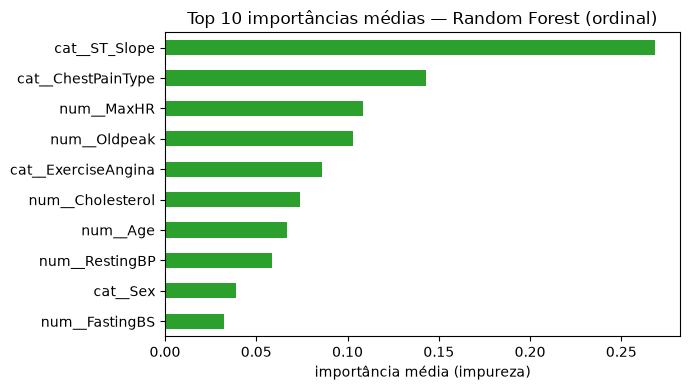

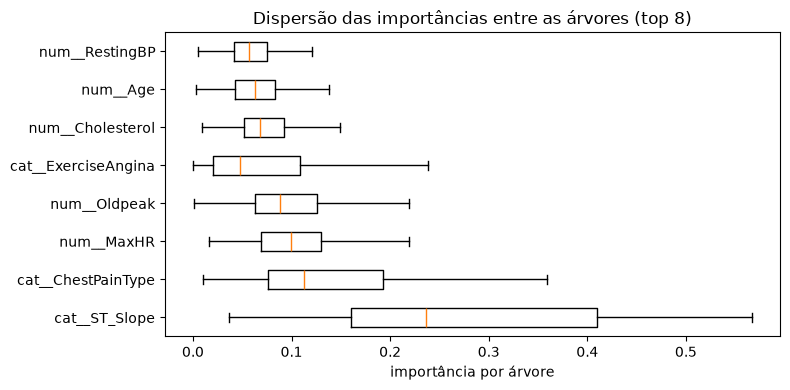

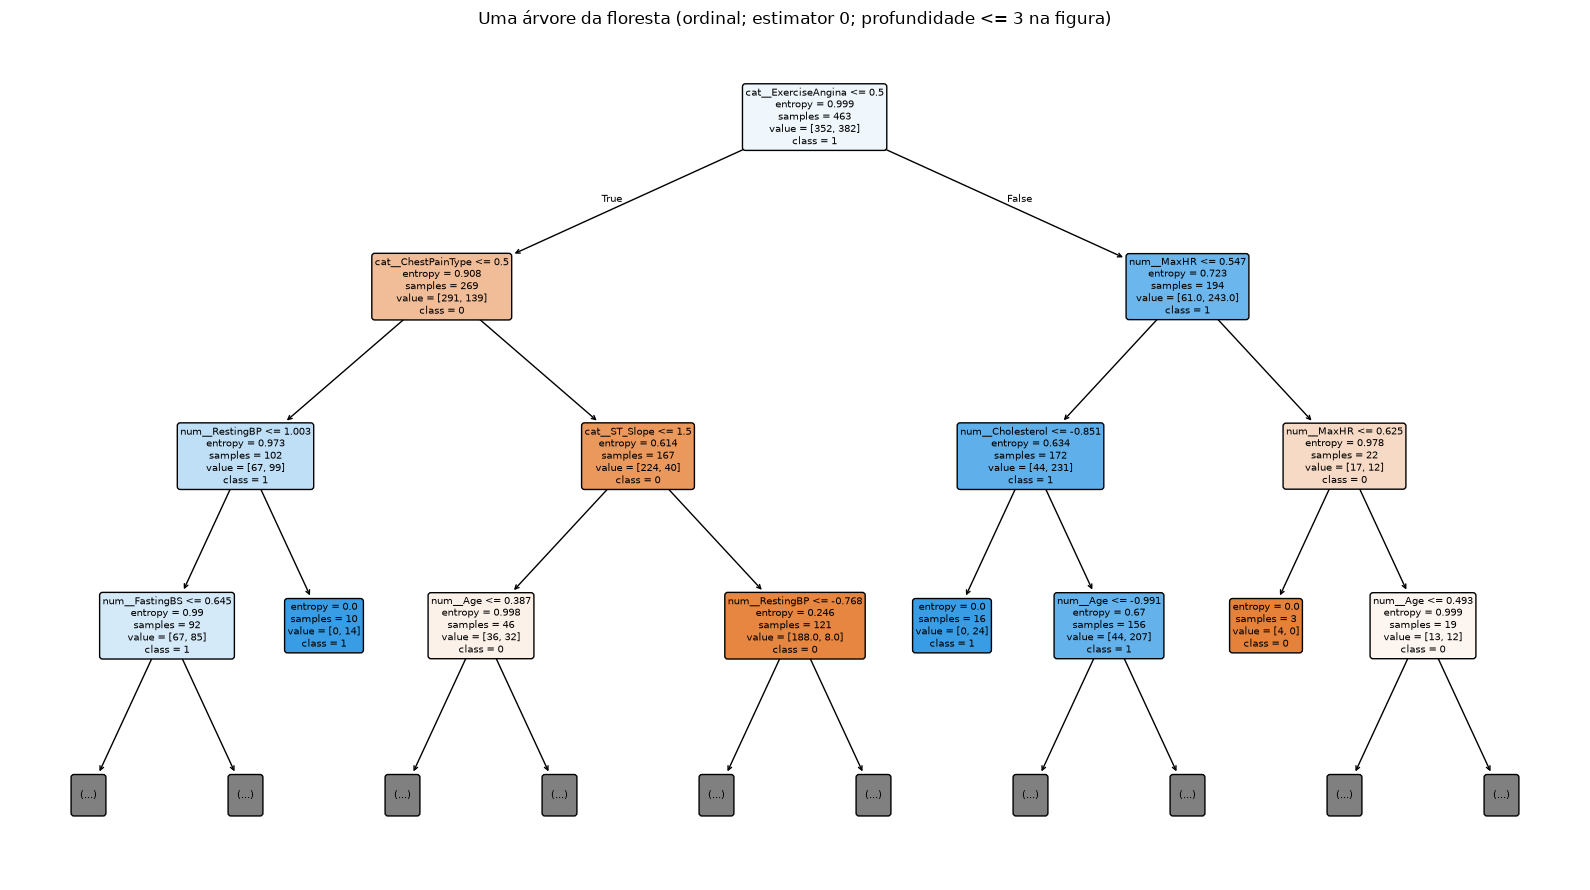

Predições idênticas com/sem StandardScaler: True


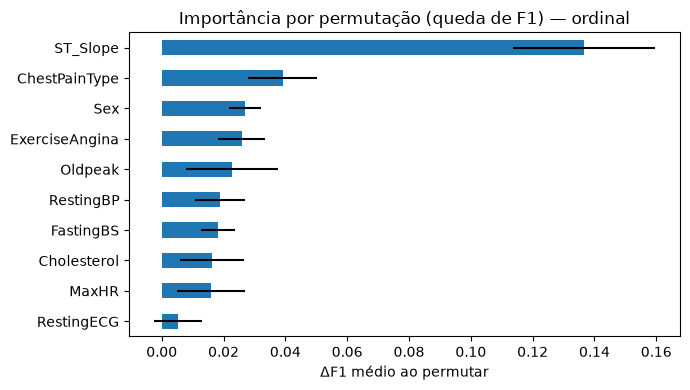

,importancia_media,importancia_desvio
ST_Slope,0.1367,0.0229
ChestPainType,0.0391,0.0112
Sex,0.0269,0.0051
ExerciseAngina,0.0259,0.0076
Oldpeak,0.0226,0.0149
RestingBP,0.0189,0.0081
FastingBS,0.0182,0.0054
Cholesterol,0.0163,0.0104
MaxHR,0.0158,0.0110
RestingECG,0.0052,0.0077


In [9]:
melhor_enc_teste = comparacao.iloc[0]['Encoding']
busca = resultados[melhor_enc_teste]['busca']
modelo = busca.best_estimator_.named_steps['modelo']
prep = busca.best_estimator_.named_steps['prep']
matriz_imp = np.vstack([t.feature_importances_ for t in modelo.estimators_])
nomes = nomes_features(prep)
imp_media = pd.Series(matriz_imp.mean(axis=0), index=nomes).sort_values(ascending=False)

print('Melhor codificação (F1 no teste):', melhor_enc_teste)
print('Nº de árvores:', len(modelo.estimators_))
print('Profundidade média das árvores: %.1f' % np.mean([t.get_depth() for t in modelo.estimators_]))
print('Folhas médias por árvore: %.1f' % np.mean([t.get_n_leaves() for t in modelo.estimators_]))
display(imp_media.head(10).to_frame('importancia_media').round(4))

# 1. top 10 importâncias médias
fig, ax = plt.subplots(figsize=(7, 4))
imp_media.head(10).sort_values().plot.barh(ax=ax, color='tab:green')
ax.set_title(f'Top 10 importâncias médias — Random Forest ({melhor_enc_teste})')
ax.set_xlabel('importância média (impureza)')
fig.tight_layout()
salva_fig(fig, 'importancia_variaveis_top10_rf.png')
plt.show()

# 2. dispersão das importâncias entre as árvores
top8 = imp_media.head(8).index.tolist()
posicoes = [nomes.index(n) for n in top8]
dados = [matriz_imp[:, p] for p in posicoes]
fig, ax = plt.subplots(figsize=(8, 4))
try:
    ax.boxplot(dados, vert=False, tick_labels=top8, showfliers=False)
except TypeError:  # matplotlib < 3.9
    ax.boxplot(dados, vert=False, labels=top8, showfliers=False)
ax.set_title('Dispersão das importâncias entre as árvores (top 8)')
ax.set_xlabel('importância por árvore')
fig.tight_layout()
salva_fig(fig, 'dispersao_importancias_rf.png')
plt.show()

# 3. uma árvore representativa da floresta (apenas ilustrativa)
fig, ax = plt.subplots(figsize=(16, 9))
plot_tree(modelo.estimators_[0], feature_names=nomes, class_names=['0', '1'],
          filled=True, rounded=True, max_depth=3, fontsize=7, ax=ax)
ax.set_title(f'Uma árvore da floresta ({melhor_enc_teste}; estimator 0; profundidade <= 3 na figura)')
fig.tight_layout()
salva_fig(fig, 'arvore_representativa_floresta.png')
plt.show()

# 4. invariância à padronização
pred_com = busca.predict(X_test)
pipe_sem = Pipeline([('prep', make_prep(melhor_enc_teste, scaler='none')),
                     ('modelo', clone(modelo))])
pipe_sem.set_params(prep__num__imp__strategy=busca.best_params_['prep__num__imp__strategy'])
pipe_sem.fit(X_train, y_train)
pred_sem = pipe_sem.predict(X_test)
print('Predições idênticas com/sem StandardScaler:',
      bool(np.array_equal(pred_com, pred_sem)))

# 5. importância por permutação (atributos originais, no teste)
perm = permutation_importance(busca.best_estimator_, X_test, y_test, scoring='f1',
                              n_repeats=10, random_state=SEED, n_jobs=1)
perm_df = (pd.DataFrame({'importancia_media': perm.importances_mean,
                         'importancia_desvio': perm.importances_std},
                        index=X_test.columns)
           .sort_values('importancia_media', ascending=False))
perm_path = PASTA_EXECUCAO / f'importancia_permutacao_rf_{melhor_enc_teste}.csv'
perm_df.to_csv(perm_path)
with mlflow.start_run(run_id=resultados[melhor_enc_teste]['run_id']):
    mlflow.log_artifact(str(perm_path))

fig, ax = plt.subplots(figsize=(7, 4))
perm_df['importancia_media'].head(10).sort_values().plot.barh(
    ax=ax, xerr=perm_df['importancia_desvio'].head(10).sort_values(), color='tab:blue')
ax.set_title(f'Importância por permutação (queda de F1) — {melhor_enc_teste}')
ax.set_xlabel('ΔF1 médio ao permutar')
fig.tight_layout()
salva_fig(fig, 'importancia_permutacao_rf.png')
plt.show()

display(perm_df.head(10).round(4))

## Ablação — seleção de atributos

Objetivo: verificar se **remover atributos** melhora o modelo, repetindo o procedimento aplicado à árvore.

- Para cada atributo, ele é removido do treino/teste e a floresta é reajustada com os **melhores hiperparâmetros** já encontrados (sem nova busca em grade, para manter a execução rápida).
- O cenário `todos` (sem remoção) serve de referência.
- A classe majoritária é a **1 (HeartDisease)**, com 55,3% dos registros; a métrica principal continua sendo o **F1 da classe 1**.
- As métricas são exibidas para **as duas classes** e para a média macro (`F1_macro`), com falsos negativos.
- Cada cenário vira uma run filha no MLflow (run pai `ablacao_atributos`).

In [10]:
# codificação usada na ablação: a de melhor F1 na validação cruzada (mesmo critério da árvore)
enc_abla = max(resultados, key=lambda e: resultados[e]['busca'].best_score_)
best_params = resultados[enc_abla]['busca'].best_params_
best_model_params = {k.replace('modelo__', ''): v
                     for k, v in best_params.items() if k.startswith('modelo__')}
imp_strategy = best_params['prep__num__imp__strategy']
print('Ablação usando encoding:', enc_abla)
print('Hiperparâmetros fixos:', best_model_params)
print('Estratégia de imputação fixa:', imp_strategy)

linhas_abla = []
with mlflow.start_run(run_name='ablacao_atributos'):
    for removido in [None] + list(X.columns):
        cols = [c for c in X.columns if c != removido]
        num_sub = [c for c in num if c in cols]
        cat_sub = [c for c in cat if c in cols]
        cenario = 'todos' if removido is None else f'sem_{removido}'

        params = dict(best_model_params)
        params['class_weight'] = None
        pipe = Pipeline([
            ('prep', make_prep_cols(enc_abla, imp_strategy=imp_strategy,
                                    num_cols=num_sub, cat_cols=cat_sub)),
            ('modelo', RandomForestClassifier(n_estimators=N_ARVORES_BUSCA,
                                              random_state=SEED, n_jobs=MODELO_JOBS, **params)),
        ])
        f1_cv = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring='f1',
                                n_jobs=-1).mean()
        pipe.fit(X_train[cols], y_train)
        pred = pipe.predict(X_test[cols])
        metricas = metricas_teste(y_test, pred)

        with mlflow.start_run(run_name=cenario, nested=True):
            mlflow.log_params({
                'atributo_removido': str(removido) if removido else 'nenhum',
                'encoding': enc_abla,
                'n_atributos': len(cols),
                'class_weight': 'None',
                'n_estimators': N_ARVORES_BUSCA,
            })
            mlflow.log_metric('f1_cv', float(f1_cv))
            mlflow.log_metrics({k: float(v) for k, v in metricas.items()})

        linhas_abla.append({
            'Cenario': cenario,
            'Atributo_removido': removido or 'nenhum',
            'F1_CV': float(f1_cv),
            **metricas,
        })
        print(f'{cenario}: ok')

ablacao = (pd.DataFrame(linhas_abla)
           .sort_values('F1_c1', ascending=False)
           .reset_index(drop=True))
ablacao.to_csv(PASTA_EXECUCAO / 'ablacao_atributos.csv', index=False)
print('\nCenários ordenados por F1 da classe 1 no teste:')
display(ablacao.round(4))

Ablação usando encoding: onehot
Hiperparâmetros fixos: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 2}
Estratégia de imputação fixa: median


todos: ok


sem_Age: ok


sem_Sex: ok


sem_ChestPainType: ok


...

sem_MaxHR: ok


sem_ExerciseAngina: ok


sem_Oldpeak: ok


sem_ST_Slope: ok

Cenários ordenados por F1 da classe 1 no teste:


,Cenario,Atributo_removido,F1_CV,Acuracia,Precisao_c0,Recall_c0,F1_c0,Precisao_c1,Recall_c1,F1_c1,F1_macro,F1_c1_IC95_inf,F1_c1_IC95_sup,TN,FP,FN,TP
0,todos,nenhum,0.8744,0.8967,0.9091,0.8537,0.8805,0.8879,0.9314,0.9091,0.8948,0.8649,0.9469,70.0,12.0,7.0,95.0
1,sem_MaxHR,MaxHR,0.8797,0.8859,0.9067,0.8293,0.8662,0.8716,0.9314,0.9005,0.8834,0.8531,0.9395,68.0,14.0,7.0,95.0
2,sem_Oldpeak,Oldpeak,0.8722,0.8859,0.9067,0.8293,0.8662,0.8716,0.9314,0.9005,0.8834,0.8557,0.9395,68.0,14.0,7.0,95.0
3,sem_Cholesterol,Cholesterol,0.8742,0.8859,0.8861,0.8537,0.8696,0.8857,0.9118,0.8986,0.8841,0.8511,0.9384,70.0,12.0,9.0,93.0
4,sem_FastingBS,FastingBS,0.8750,0.8859,0.8861,0.8537,0.8696,0.8857,0.9118,0.8986,0.8841,0.8493,0.9390,70.0,12.0,9.0,93.0
5,sem_Age,Age,0.8740,0.8804,0.8947,0.8293,0.8608,0.8704,0.9216,0.8952,0.8780,0.8485,0.9375,68.0,14.0,8.0,94.0
6,sem_RestingBP,RestingBP,0.8716,0.8750,0.8831,0.8293,0.8553,0.8692,0.9118,0.8900,0.8726,0.8390,0.9309,68.0,14.0,9.0,93.0
7,sem_RestingECG,RestingECG,0.8767,0.8696,0.8625,0.8415,0.8519,0.8750,0.8922,0.8835,0.8677,0.8283,0.9238,69.0,13.0,11.0,91.0
8,sem_Sex,Sex,0.8689,0.8641,0.8701,0.8171,0.8428,0.8598,0.9020,0.8804,0.8616,0.8302,0.9246,67.0,15.0,10.0,92.0
9,sem_ExerciseAngina,ExerciseAngina,0.8752,0.8478,0.8293,0.8293,0.8293,0.8627,0.8627,0.8627,0.8460,0.8040,0.9068,68.0,14.0,14.0,88.0


## Engenharia de features (razões/interações clínicas)

As mesmas 5 features derivadas da árvore são testadas aqui. Em uma floresta, a expectativa é diferente da árvore única: o ensemble já combina cortes de várias árvores, então o ganho das razões tende a ser menor — hipótese que esta seção verifica.

- `FC_pct_teorica = MaxHR / (220 - Age)`
- `Chol_por_Idade = Cholesterol / Age`
- `BP_por_Idade = RestingBP / Age`
- `Oldpeak_por_FC = Oldpeak / MaxHR`
- `Angina_x_Oldpeak = (ExerciseAngina == 'Y') * Oldpeak`

As razões são calculadas linha a linha (sem vazamento) e entram no pipeline numérico.

In [11]:
# features clínicas derivadas (linha a linha, sem vazamento)
df_eng = df.copy()
df_eng['FC_pct_teorica']   = df_eng['MaxHR'] / (220 - df_eng['Age'])
df_eng['Chol_por_Idade']   = df_eng['Cholesterol'] / df_eng['Age']
df_eng['BP_por_Idade']     = df_eng['RestingBP'] / df_eng['Age']
df_eng['Oldpeak_por_FC']   = df_eng['Oldpeak'] / df_eng['MaxHR'].replace(0, np.nan)
df_eng['Angina_x_Oldpeak'] = (df_eng['ExerciseAngina'] == 'Y').astype(int) * df_eng['Oldpeak']


def avalia_conjunto(X_tr, X_te, y_tr, y_te, nome):
    num_c = X_tr.select_dtypes(include='number').columns.tolist()
    cat_c = X_tr.select_dtypes(include=['object', 'category']).columns.tolist()
    params = dict(best_model_params)
    params['class_weight'] = None
    pipe = Pipeline([
        ('prep', make_prep_cols(enc_abla, imp_strategy=imp_strategy,
                                num_cols=num_c, cat_cols=cat_c)),
        ('modelo', RandomForestClassifier(n_estimators=N_ARVORES_BUSCA,
                                          random_state=SEED, n_jobs=MODELO_JOBS, **params)),
    ])
    f1_cv = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring='f1', n_jobs=-1).mean()
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    m = metricas_teste(y_te, pred)
    with mlflow.start_run(run_name=nome, nested=True):
        mlflow.log_params({'engenharia': nome, 'n_atributos': X_tr.shape[1],
                           'encoding': enc_abla, 'class_weight': 'None',
                           'n_estimators': N_ARVORES_BUSCA})
        mlflow.log_metric('f1_cv', float(f1_cv))
        mlflow.log_metrics({k: float(v) for k, v in m.items()})
    return {'Cenario': nome, 'N_atributos': X_tr.shape[1], 'F1_CV': float(f1_cv), **m}


with mlflow.start_run(run_name='engenharia_features'):
    res_sem = avalia_conjunto(X_train, X_test, y_train, y_test, 'sem_engenharia')
    X_eng = df_eng.drop(columns='HeartDisease')
    res_com = avalia_conjunto(X_eng.loc[X_train.index], X_eng.loc[X_test.index],
                              y_train, y_test, 'com_engenharia')

engenharia = pd.DataFrame([res_sem, res_com])
engenharia.to_csv(PASTA_EXECUCAO / 'engenharia_features.csv', index=False)
print('Comparação com/sem engenharia de features (Random Forest):')
display(engenharia.round(4))

Comparação com/sem engenharia de features (Random Forest):


,Cenario,N_atributos,F1_CV,Acuracia,Precisao_c0,Recall_c0,F1_c0,Precisao_c1,Recall_c1,F1_c1,F1_macro,F1_c1_IC95_inf,F1_c1_IC95_sup,TN,FP,FN,TP
0,sem_engenharia,11,0.8744,0.8967,0.9091,0.8537,0.8805,0.8879,0.9314,0.9091,0.8948,0.8649,0.9469,70.0,12.0,7.0,95.0
1,com_engenharia,16,0.8775,0.8370,0.8333,0.7927,0.8125,0.8396,0.8725,0.8558,0.8341,0.7978,0.9048,65.0,17.0,13.0,89.0


## Sensibilidade ao número de árvores

O número de árvores (`n_estimators`) é o hiperparâmetro mais característico do Random Forest: mais árvores reduzem a variância das predições, mas com retorno decrescente e custo crescente. Como ele foi fixado em 300 na busca (para manter o mesmo orçamento da árvore), esta seção mede o efeito de 100, 300, 500 e 800 árvores com os **melhores hiperparâmetros** encontrados. Cada valor é uma run filha de `sensibilidade_n_estimators`.

100 árvores: F1_CV 0.8741 | F1_c1 teste 0.8878 | FN 11


300 árvores: F1_CV 0.8809 | F1_c1 teste 0.8932 | FN 10


500 árvores: F1_CV 0.8790 | F1_c1 teste 0.8976 | FN 10


800 árvores: F1_CV 0.8800 | F1_c1 teste 0.8976 | FN 10


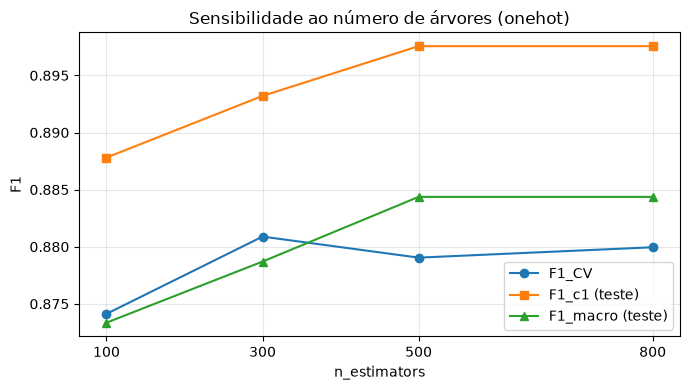

,N_arvores,F1_CV,Acuracia,Precisao_c0,Recall_c0,F1_c0,Precisao_c1,Recall_c1,F1_c1,F1_macro,TN,FP,FN,TP
0,100,0.8741,0.8750,0.8642,0.8537,0.8589,0.8835,0.8922,0.8878,0.8734,70.0,12.0,11.0,91.0
1,300,0.8809,0.8804,0.8750,0.8537,0.8642,0.8846,0.9020,0.8932,0.8787,70.0,12.0,10.0,92.0
2,500,0.8790,0.8859,0.8765,0.8659,0.8712,0.8932,0.9020,0.8976,0.8844,71.0,11.0,10.0,92.0
3,800,0.8800,0.8859,0.8765,0.8659,0.8712,0.8932,0.9020,0.8976,0.8844,71.0,11.0,10.0,92.0


In [12]:
enc_sens = enc_abla                      # codificação de melhor F1 na CV
params_sens = dict(best_model_params)    # mantém o class_weight escolhido pela grade
linhas_sens = []

with mlflow.start_run(run_name='sensibilidade_n_estimators'):
    for n in [100, 300, 500, 800]:
        pipe = Pipeline([
            ('prep', make_prep_cols(enc_sens, imp_strategy=imp_strategy)),
            ('modelo', RandomForestClassifier(n_estimators=n, random_state=SEED,
                                              n_jobs=MODELO_JOBS, **params_sens)),
        ])
        f1_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1',
                                n_jobs=-1).mean()
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        m = metricas_teste(y_test, pred)
        with mlflow.start_run(run_name=f'arvores_{n}', nested=True):
            mlflow.log_param('n_estimators', n)
            mlflow.log_param('encoding', enc_sens)
            mlflow.log_metric('f1_cv', float(f1_cv))
            mlflow.log_metrics({k: float(v) for k, v in m.items()})
        linhas_sens.append({'N_arvores': n, 'F1_CV': float(f1_cv), **m})
        print(f'{n} árvores: F1_CV {f1_cv:.4f} | F1_c1 teste {m["F1_c1"]:.4f} | FN {int(m["FN"])}')

sensibilidade = pd.DataFrame(linhas_sens)
sensibilidade.to_csv(PASTA_EXECUCAO / 'sensibilidade_n_estimators.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sensibilidade['N_arvores'], sensibilidade['F1_CV'], marker='o', label='F1_CV')
ax.plot(sensibilidade['N_arvores'], sensibilidade['F1_c1'], marker='s', label='F1_c1 (teste)')
ax.plot(sensibilidade['N_arvores'], sensibilidade['F1_macro'], marker='^', label='F1_macro (teste)')
ax.set_xlabel('n_estimators')
ax.set_ylabel('F1')
ax.set_title(f'Sensibilidade ao número de árvores ({enc_sens})')
ax.set_xticks(sensibilidade['N_arvores'])
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
salva_fig(fig, 'sensibilidade_n_arvores.png')
plt.show()

display(sensibilidade.drop(columns=['F1_c1_IC95_inf', 'F1_c1_IC95_sup']).round(4))

## Comparação Random Forest × Árvore de Decisão

Esta seção materializa o objetivo do trabalho: comparar as duas abordagens sobre **o mesmo split, a mesma validação cruzada e as mesmas métricas**.

- Os resultados da árvore são lidos da execução mais recente em `resultados/execucao_<timestamp>/` (com fallback para os artefatos registrados no MLflow no experimento `heart_failure_arvore_decisao`).
- A tabela consolidada tem uma linha por **(modelo, bloco, cenário)**, com F1 da classe 1, F1 macro, acurácia, recall da classe 1, falsos negativos e falsos positivos.
- Os falsos negativos/positivos da árvore são reconstruídos a partir de `Recall_c1` e `Precisao_c1` (o teste tem 102 pacientes da classe 1 e 82 da classe 0, os mesmos nas duas abordagens).
- Os deltas (floresta − árvore) são registrados como métricas na run `comparacao_rf_vs_arvore`.

In [13]:
def localiza_resultados_arvore():
    """Pasta com os resultados da árvore (local ou, em último caso, artefatos do MLflow)."""
    for pasta in sorted(PASTA_RESULTADOS_ARVORE.glob('execucao_*'), reverse=True):
        if (pasta / 'comparacao_arvore_decisao.csv').exists() and \
           (pasta / 'engenharia_features.csv').exists():
            return pasta
    try:
        runs = mlflow.search_runs(experiment_names=[EXPERIMENTO_ARVORE])
        runs = runs[runs['tags.mlflow.runName'] == 'relatorio_artefatos']
        if len(runs):
            destino = Path(mlflow.artifacts.download_artifacts(run_id=runs.iloc[0]['run_id']))
            if (destino / 'comparacao_arvore_decisao.csv').exists():
                return destino
    except Exception as erro:
        print('Falha ao buscar artefatos da árvore no MLflow:', erro)
    raise FileNotFoundError('Resultados da árvore não encontrados em ' + str(PASTA_RESULTADOS_ARVORE))


PASTA_ARVORE = localiza_resultados_arvore()
print('Resultados da árvore usados na comparação:', PASTA_ARVORE)

comp_arv = pd.read_csv(PASTA_ARVORE / 'comparacao_arvore_decisao.csv')
eng_arv = pd.read_csv(PASTA_ARVORE / 'engenharia_features.csv')
abla_arv = pd.read_csv(PASTA_ARVORE / 'ablacao_atributos.csv')

N_C1_TESTE = int((y_test == 1).sum())


def fn_fp_por_metricas(recall_c1, precisao_c1, n_c1=N_C1_TESTE):
    """Reconstrói FN e FP a partir de recall/precisão da classe 1."""
    tp = int(round(float(recall_c1) * n_c1))
    fn = n_c1 - tp
    fp = int(round(tp / float(precisao_c1) - tp)) if precisao_c1 > 0 else n_c1
    return fn, fp


COLUNAS = ['Modelo', 'Bloco', 'Cenario', 'F1_CV', 'Acuracia', 'Precisao_c1', 'Recall_c1',
           'F1_c0', 'F1_c1', 'F1_macro', 'FN', 'FP', 'IC95_inf', 'IC95_sup']
ARVORE, RF = 'Arvore de Decisao', 'Random Forest'
linhas_tidy = []

# 1) codificação one-hot x ordinal
for _, r in comp_arv.iterrows():
    fn, fp = fn_fp_por_metricas(r['Recall_c1'], r['Precisao_c1'])
    linhas_tidy.append({'Modelo': ARVORE, 'Bloco': 'codificacao', 'Cenario': r['Encoding'],
                        'F1_CV': r['F1_CV'], 'Acuracia': r['Acuracia_teste'],
                        'Precisao_c1': r['Precisao_c1'], 'Recall_c1': r['Recall_c1'],
                        'F1_c0': r['F1_c0'], 'F1_c1': r['F1_c1'], 'F1_macro': r['F1_macro'],
                        'FN': fn, 'FP': fp,
                        'IC95_inf': r['F1_c1_IC95_inf'], 'IC95_sup': r['F1_c1_IC95_sup']})
for _, r in comparacao.iterrows():
    linhas_tidy.append({'Modelo': RF, 'Bloco': 'codificacao', 'Cenario': r['Encoding'],
                        'F1_CV': r['F1_CV'], 'Acuracia': r['Acuracia'],
                        'Precisao_c1': r['Precisao_c1'], 'Recall_c1': r['Recall_c1'],
                        'F1_c0': r['F1_c0'], 'F1_c1': r['F1_c1'], 'F1_macro': r['F1_macro'],
                        'FN': r['FN'], 'FP': r['FP'],
                        'IC95_inf': r['F1_c1_IC95_inf'], 'IC95_sup': r['F1_c1_IC95_sup']})

Resultados da árvore usados na comparação: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/resultados/execucao_20261026_075517


In [14]:
# 2) engenharia de features
for _, r in eng_arv.iterrows():
    fn, fp = fn_fp_por_metricas(r['Recall_c1'], r['Precisao_c1'])
    linhas_tidy.append({'Modelo': ARVORE, 'Bloco': 'engenharia', 'Cenario': r['Cenario'],
                        'F1_CV': np.nan, 'Acuracia': r['Acuracia'],
                        'Precisao_c1': r['Precisao_c1'], 'Recall_c1': r['Recall_c1'],
                        'F1_c0': r['F1_c0'], 'F1_c1': r['F1_c1'], 'F1_macro': r['F1_macro'],
                        'FN': fn, 'FP': fp, 'IC95_inf': np.nan, 'IC95_sup': np.nan})
for _, r in engenharia.iterrows():
    linhas_tidy.append({'Modelo': RF, 'Bloco': 'engenharia', 'Cenario': r['Cenario'],
                        'F1_CV': r['F1_CV'], 'Acuracia': r['Acuracia'],
                        'Precisao_c1': r['Precisao_c1'], 'Recall_c1': r['Recall_c1'],
                        'F1_c0': r['F1_c0'], 'F1_c1': r['F1_c1'], 'F1_macro': r['F1_macro'],
                        'FN': r['FN'], 'FP': r['FP'], 'IC95_inf': np.nan, 'IC95_sup': np.nan})

# 3) ablação (um atributo removido por vez)
for _, r in abla_arv.iterrows():
    fn, fp = fn_fp_por_metricas(r['Recall_c1'], r['Precisao_c1'])
    linhas_tidy.append({'Modelo': ARVORE, 'Bloco': 'ablacao', 'Cenario': r['Cenario'],
                        'F1_CV': np.nan, 'Acuracia': r['Acuracia'],
                        'Precisao_c1': r['Precisao_c1'], 'Recall_c1': r['Recall_c1'],
                        'F1_c0': r['F1_c0'], 'F1_c1': r['F1_c1'], 'F1_macro': r['F1_macro'],
                        'FN': fn, 'FP': fp, 'IC95_inf': np.nan, 'IC95_sup': np.nan})
for _, r in ablacao.iterrows():
    linhas_tidy.append({'Modelo': RF, 'Bloco': 'ablacao', 'Cenario': r['Cenario'],
                        'F1_CV': r['F1_CV'], 'Acuracia': r['Acuracia'],
                        'Precisao_c1': r['Precisao_c1'], 'Recall_c1': r['Recall_c1'],
                        'F1_c0': r['F1_c0'], 'F1_c1': r['F1_c1'], 'F1_macro': r['F1_macro'],
                        'FN': r['FN'], 'FP': r['FP'], 'IC95_inf': np.nan, 'IC95_sup': np.nan})

comparacao_rf_arvore = pd.DataFrame(linhas_tidy, columns=COLUNAS)
comparacao_rf_arvore.to_csv(PASTA_EXECUCAO / 'comparacao_rf_vs_arvore.csv', index=False)

cmp_cod = (comparacao_rf_arvore[comparacao_rf_arvore['Bloco'] == 'codificacao']
           .sort_values(['Cenario', 'Modelo']).reset_index(drop=True))
cmp_cod.to_csv(PASTA_EXECUCAO / 'comparacao_codificacao_rf_vs_arvore.csv', index=False)

cmp_eng = (comparacao_rf_arvore[comparacao_rf_arvore['Bloco'] == 'engenharia']
           .sort_values(['Cenario', 'Modelo']).reset_index(drop=True))
cmp_eng.to_csv(PASTA_EXECUCAO / 'comparacao_engenharia_rf_vs_arvore.csv', index=False)

# ablação em formato largo: uma linha por cenário, colunas por modelo e deltas
abl = comparacao_rf_arvore[comparacao_rf_arvore['Bloco'] == 'ablacao']
cmp_abla = abl.pivot_table(index='Cenario', columns='Modelo', values='F1_c1')
cmp_abla.columns = [f'F1_c1_{c}' for c in cmp_abla.columns]
for coluna in ['F1_macro', 'Recall_c1', 'Acuracia']:
    p = abl.pivot_table(index='Cenario', columns='Modelo', values=coluna)
    p.columns = [f'{coluna}_{c}' for c in p.columns]
    cmp_abla = cmp_abla.join(p)
cmp_abla['delta_F1_c1'] = cmp_abla[f'F1_c1_{RF}'] - cmp_abla[f'F1_c1_{ARVORE}']
cmp_abla['delta_F1_macro'] = cmp_abla[f'F1_macro_{RF}'] - cmp_abla[f'F1_macro_{ARVORE}']
cmp_abla = cmp_abla.sort_values('delta_F1_c1', ascending=False).reset_index()
cmp_abla.to_csv(PASTA_EXECUCAO / 'comparacao_ablacao_rf_vs_arvore.csv', index=False)

print('Codificação — árvore x floresta')
display(cmp_cod.round(4))
print('Engenharia de features — árvore x floresta')
display(cmp_eng.round(4))
print('Ablação — delta de F1_c1 (floresta − árvore)')
display(cmp_abla.round(4))

Codificação — árvore x floresta


,Modelo,Bloco,Cenario,F1_CV,Acuracia,Precisao_c1,Recall_c1,F1_c0,F1_c1,F1_macro,FN,FP,IC95_inf,IC95_sup
0,Arvore de Decisao,codificacao,onehot,0.8550,0.8207,0.8710,0.7941,0.8092,0.8308,0.8200,21.0,12.0,0.7650,0.8865
1,Random Forest,codificacao,onehot,0.8809,0.8804,0.8846,0.9020,0.8642,0.8932,0.8787,10.0,12.0,0.8442,0.9347
2,Arvore de Decisao,codificacao,ordinal,0.8604,0.8098,0.7913,0.8922,0.7682,0.8387,0.8035,11.0,24.0,0.7817,0.8879
3,Random Forest,codificacao,ordinal,0.8799,0.8859,0.9091,0.8824,0.8743,0.8955,0.8849,12.0,9.0,0.8469,0.9368


Engenharia de features — árvore x floresta


,Modelo,Bloco,Cenario,F1_CV,Acuracia,Precisao_c1,Recall_c1,F1_c0,F1_c1,F1_macro,FN,FP,IC95_inf,IC95_sup
0,Arvore de Decisao,engenharia,com_engenharia,NaN,0.8261,0.7966,0.9216,0.7838,0.8545,0.8192,8.0,24.0,NaN,NaN
1,Random Forest,engenharia,com_engenharia,0.8775,0.8370,0.8396,0.8725,0.8125,0.8558,0.8341,13.0,17.0,NaN,NaN
2,Arvore de Decisao,engenharia,sem_engenharia,NaN,0.8098,0.7913,0.8922,0.7682,0.8387,0.8035,11.0,24.0,NaN,NaN
3,Random Forest,engenharia,sem_engenharia,0.8744,0.8967,0.8879,0.9314,0.8805,0.9091,0.8948,7.0,12.0,NaN,NaN


Ablação — delta de F1_c1 (floresta − árvore)


,Cenario,F1_c1_Arvore de Decisao,F1_c1_Random Forest,F1_macro_Arvore de Decisao,F1_macro_Random Forest,Recall_c1_Arvore de Decisao,Recall_c1_Random Forest,Acuracia_Arvore de Decisao,Acuracia_Random Forest,delta_F1_c1,delta_F1_macro
0,sem_Oldpeak,0.7647,0.9005,0.7360,0.8834,0.7647,0.9314,0.7391,0.8859,0.1358,0.1473
1,sem_RestingECG,0.7647,0.8835,0.7360,0.8677,0.7647,0.8922,0.7391,0.8696,0.1188,0.1317
2,sem_Sex,0.7647,0.8804,0.7360,0.8616,0.7647,0.9020,0.7391,0.8641,0.1157,0.1256
3,sem_MaxHR,0.7890,0.9005,0.7412,0.8834,0.8431,0.9314,0.7500,0.8859,0.1115,0.1422
4,sem_ChestPainType,0.7647,0.8400,0.7360,0.8248,0.7647,0.8235,0.7391,0.8261,0.0753,0.0888
5,sem_Age,0.8229,0.8952,0.8149,0.8780,0.7745,0.9216,0.8152,0.8804,0.0723,0.0631
6,sem_Cholesterol,0.8272,0.8986,0.8204,0.8841,0.7745,0.9118,0.8207,0.8859,0.0713,0.0637
7,sem_FastingBS,0.8272,0.8986,0.8204,0.8841,0.7745,0.9118,0.8207,0.8859,0.0713,0.0637
8,todos,0.8387,0.9091,0.8035,0.8948,0.8922,0.9314,0.8098,0.8967,0.0704,0.0913
9,sem_ST_Slope,0.7897,0.8600,0.7764,0.8467,0.7549,0.8431,0.7772,0.8478,0.0703,0.0703


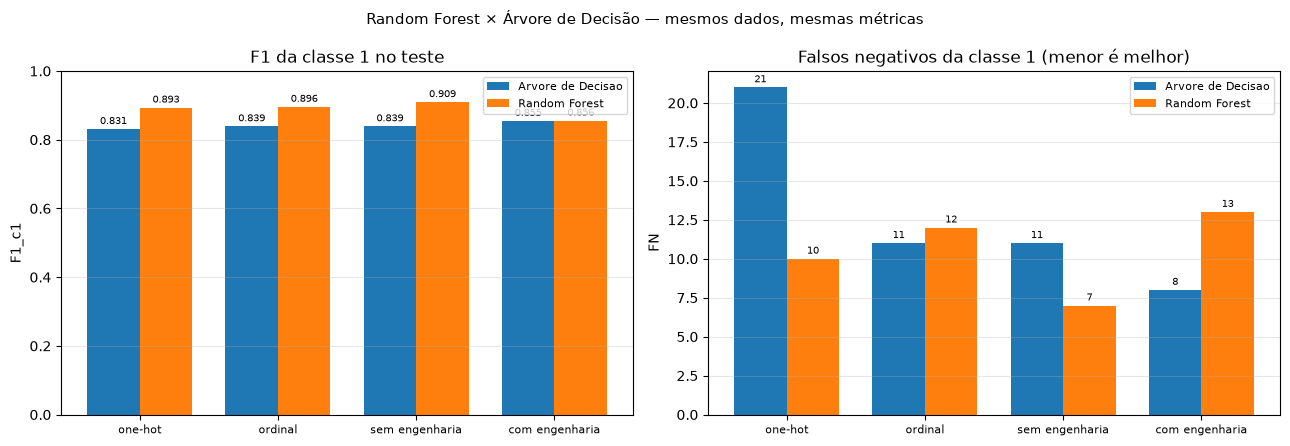

Resumo da comparação (floresta − árvore):


,Cenario,F1_c1_arvore,F1_c1_rf,FN_arvore,FN_rf,delta_F1_c1,delta_FN
0,one-hot,0.8308,0.8932,21.0,10.0,0.0624,-11.0
1,ordinal,0.8387,0.8955,11.0,12.0,0.0568,1.0
2,sem engenharia,0.8387,0.9091,11.0,7.0,0.0704,-4.0
3,com engenharia,0.8545,0.8558,8.0,13.0,0.0012,5.0


In [15]:
cenarios_plot = ['onehot', 'ordinal', 'sem_engenharia', 'com_engenharia']
rotulos = ['one-hot', 'ordinal', 'sem engenharia', 'com engenharia']


def valor(modelo, cenario, coluna):
    sub = comparacao_rf_arvore[(comparacao_rf_arvore['Modelo'] == modelo) &
                               (comparacao_rf_arvore['Cenario'] == cenario)]
    return float(sub[coluna].iloc[0]) if len(sub) else np.nan


largura = 0.38
x = np.arange(len(cenarios_plot))
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
for i, modelo in enumerate([ARVORE, RF]):
    f1 = [valor(modelo, c, 'F1_c1') for c in cenarios_plot]
    fn = [valor(modelo, c, 'FN') for c in cenarios_plot]
    pos = x + (i - 0.5) * largura
    b1 = eixos[0].bar(pos, f1, largura, label=modelo)
    b2 = eixos[1].bar(pos, fn, largura, label=modelo)
    eixos[0].bar_label(b1, fmt='%.3f', fontsize=7, padding=2)
    eixos[1].bar_label(b2, fmt='%d', fontsize=7, padding=2)

eixos[0].set_title('F1 da classe 1 no teste')
eixos[0].set_ylabel('F1_c1')
eixos[0].set_ylim(0, 1.0)
eixos[1].set_title('Falsos negativos da classe 1 (menor é melhor)')
eixos[1].set_ylabel('FN')
for ax in eixos:
    ax.set_xticks(x)
    ax.set_xticklabels(rotulos, fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle('Random Forest × Árvore de Decisão — mesmos dados, mesmas métricas', fontsize=11)
fig.tight_layout()
salva_fig(fig, 'comparacao_rf_vs_arvore.png')
plt.show()

# deltas e registro no MLflow
with mlflow.start_run(run_name='comparacao_rf_vs_arvore'):
    mlflow.log_param('modelo_floresta', f'RandomForestClassifier(n_estimators={N_ARVORES_BUSCA})')
    mlflow.log_param('modelo_arvore', 'DecisionTreeClassifier')
    mlflow.log_param('fonte_resultados_arvore', str(PASTA_ARVORE))
    for c in cenarios_plot:
        mlflow.log_metric(f'delta_f1_c1_{c}',
                          valor(RF, c, 'F1_c1') - valor(ARVORE, c, 'F1_c1'))
        mlflow.log_metric(f'delta_f1_macro_{c}',
                          valor(RF, c, 'F1_macro') - valor(ARVORE, c, 'F1_macro'))
        mlflow.log_metric(f'delta_recall_c1_{c}',
                          valor(RF, c, 'Recall_c1') - valor(ARVORE, c, 'Recall_c1'))
        mlflow.log_metric(f'delta_fn_{c}',
                          valor(RF, c, 'FN') - valor(ARVORE, c, 'FN'))
    mlflow.log_metric('melhor_f1_c1_rf', float(comparacao['F1_c1'].max()))
    mlflow.log_metric('melhor_f1_c1_arvore', float(comp_arv['F1_c1'].max()))
    for arquivo in ['comparacao_rf_vs_arvore.csv', 'comparacao_codificacao_rf_vs_arvore.csv',
                    'comparacao_engenharia_rf_vs_arvore.csv',
                    'comparacao_ablacao_rf_vs_arvore.csv', 'comparacao_rf_vs_arvore.png']:
        mlflow.log_artifact(str(PASTA_EXECUCAO / arquivo))

resumo_cmp = pd.DataFrame({
    'Cenario': rotulos,
    'F1_c1_arvore': [valor(ARVORE, c, 'F1_c1') for c in cenarios_plot],
    'F1_c1_rf': [valor(RF, c, 'F1_c1') for c in cenarios_plot],
    'FN_arvore': [valor(ARVORE, c, 'FN') for c in cenarios_plot],
    'FN_rf': [valor(RF, c, 'FN') for c in cenarios_plot],
})
resumo_cmp['delta_F1_c1'] = resumo_cmp['F1_c1_rf'] - resumo_cmp['F1_c1_arvore']
resumo_cmp['delta_FN'] = resumo_cmp['FN_rf'] - resumo_cmp['FN_arvore']
print('Resumo da comparação (floresta − árvore):')
display(resumo_cmp.round(4))

## Exportar resultados

Salva as métricas, as variações de busca, a ablação, a engenharia, a sensibilidade ao número de árvores e a comparação com a árvore; registra os arquivos como artefatos no MLflow. Tudo fica em `docs/handle_forest/resultados/execucao_<timestamp>/` (as figuras também são copiadas para `docs/handle_forest/figuras/`).

In [16]:
comparacao.to_csv(PASTA_EXECUCAO / 'comparacao_random_forest.csv', index=False)

parametros = {}
for enc, item in resultados.items():
    parametros[enc] = {
        'imputacao': str(item['busca'].best_params_['prep__num__imp__strategy']),
        'n_estimators': N_ARVORES_BUSCA,
        'oob_score': None if np.isnan(item['oob']) else round(item['oob'], 4),
        **{k.replace('modelo__', ''): str(v)
           for k, v in item['busca'].best_params_.items() if k.startswith('modelo__')},
    }

with open(PASTA_EXECUCAO / 'melhores_hiperparametros_random_forest.json', 'w', encoding='utf-8') as f:
    json.dump(parametros, f, ensure_ascii=False, indent=2)

arquivos = [
    PASTA_EXECUCAO / 'comparacao_random_forest.csv',
    PASTA_EXECUCAO / 'melhores_hiperparametros_random_forest.json',
    PASTA_EXECUCAO / 'ablacao_atributos.csv',
    PASTA_EXECUCAO / 'engenharia_features.csv',
    PASTA_EXECUCAO / 'sensibilidade_n_estimators.csv',
    PASTA_EXECUCAO / 'comparacao_rf_vs_arvore.csv',
    PASTA_EXECUCAO / 'comparacao_codificacao_rf_vs_arvore.csv',
    PASTA_EXECUCAO / 'comparacao_engenharia_rf_vs_arvore.csv',
    PASTA_EXECUCAO / 'comparacao_ablacao_rf_vs_arvore.csv',
    PASTA_EXECUCAO / 'importancia_variaveis_top10_rf.png',
    PASTA_EXECUCAO / 'dispersao_importancias_rf.png',
    PASTA_EXECUCAO / 'arvore_representativa_floresta.png',
    PASTA_EXECUCAO / 'importancia_permutacao_rf.png',
    PASTA_EXECUCAO / 'sensibilidade_n_arvores.png',
    PASTA_EXECUCAO / 'comparacao_rf_vs_arvore.png',
]
arquivos = [a for a in arquivos if Path(a).exists()]

zip_path = PASTA_EXECUCAO / 'resultados_random_forest.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for a in arquivos:
        z.write(a, arcname=Path(a).name)

with mlflow.start_run(run_name='relatorio_artefatos'):
    for a in arquivos + [zip_path]:
        mlflow.log_artifact(str(a))
    mlflow.log_param('pasta_execucao', str(PASTA_EXECUCAO))
    mlflow.log_metric('n_arquivos', len(arquivos))

print('Pasta da execução:', PASTA_EXECUCAO)
print('Criados:', ', '.join(Path(a).name for a in arquivos), '+', zip_path.name)

Pasta da execução: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/handle_forest/resultados/execucao_20261030_205115
Criados: comparacao_random_forest.csv, melhores_hiperparametros_random_forest.json, ablacao_atributos.csv, engenharia_features.csv, sensibilidade_n_estimators.csv, comparacao_rf_vs_arvore.csv, comparacao_codificacao_rf_vs_arvore.csv, comparacao_engenharia_rf_vs_arvore.csv, comparacao_ablacao_rf_vs_arvore.csv, importancia_variaveis_top10_rf.png, dispersao_importancias_rf.png, arvore_representativa_floresta.png, importancia_permutacao_rf.png, sensibilidade_n_arvores.png, comparacao_rf_vs_arvore.png + resultados_random_forest.zip


## Consultar e comparar os resultados no MLflow

No terminal, na raiz do projeto:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Abra <http://127.0.0.1:5000> e filtre por experimento:

- **`heart_failure_random_forest`** — runs `random_forest_onehot`, `random_forest_ordinal`, `baseline_classe_majoritaria`, `ablacao_atributos` (com as runs filhas de cada cenário), `engenharia_features` (`sem_engenharia`/`com_engenharia`), `sensibilidade_n_estimators` (`arvores_100`…`arvores_800`), `comparacao_rf_vs_arvore` e `relatorio_artefatos`;
- **`heart_failure_arvore_decisao`** — o experimento da árvore, no mesmo banco.

Na aba *Compare* da UI é possível marcar runs dos dois experimentos e comparar parâmetros, métricas (F1_c1, F1_macro, recall_c1, FN, OOB, tempo de busca) e artefatos lado a lado. A célula abaixo exporta as tabelas de runs dos dois experimentos para CSV.

In [17]:
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento (floresta):', EXPERIMENTO)
print('Experimento (árvore):', EXPERIMENTO_ARVORE)

runs_rf = mlflow.search_runs(experiment_names=[EXPERIMENTO])
runs_arv = mlflow.search_runs(experiment_names=[EXPERIMENTO_ARVORE])
print('\nRuns no experimento da floresta:', len(runs_rf))
print('Runs no experimento da árvore:', len(runs_arv))

runs_rf.to_csv(PASTA_DOCS / 'mlflow_runs_random_forest.csv', index=False)
runs_arv.to_csv(PASTA_DOCS / 'mlflow_runs_arvore_decisao.csv', index=False)

colunas_rf = [c for c in ['run_id', 'tags.mlflow.runName', 'status',
                          'metrics.f1_cv', 'metrics.F1_c1', 'metrics.F1_macro',
                          'metrics.FN', 'metrics.oob_score'] if c in runs_rf.columns]
display(runs_rf[colunas_rf].sort_values('metrics.f1_cv', ascending=False)
        .head(15).round(4).reset_index(drop=True))

# conferência rápida: melhor F1_c1 de cada abordagem no teste
print('Melhor F1_c1 no teste — floresta: %.4f' % comparacao['F1_c1'].max())
print('Melhor F1_c1 no teste — árvore:   %.4f' % comp_arv['F1_c1'].max())
print('Melhor F1_cv  — floresta: %.4f' % max(item['busca'].best_score_ for item in resultados.values()))
print('Melhor F1_cv  — árvore:   %.4f' % comp_arv['F1_CV'].max())

Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento (floresta): heart_failure_random_forest
Experimento (árvore): heart_failure_arvore_decisao

Runs no experimento da floresta: 26
Runs no experimento da árvore: 111


,run_id,tags.mlflow.runName,status,metrics.f1_cv,metrics.F1_c1,metrics.F1_macro,metrics.FN,metrics.oob_score
0,10ab57b931014dada0c253628ebc154f,random_forest_onehot,FINISHED,0.8809,0.8932,0.8787,10.0,0.8583
1,54490eff1f86450aa25a1f4af0977c6f,arvores_300,FINISHED,0.8809,0.8932,0.8787,10.0,NaN
2,1160312a39a74955afbcc41fe705def0,arvores_800,FINISHED,0.8800,0.8976,0.8844,10.0,NaN
3,80c484b6840c453591aa04b1c46b00c6,random_forest_ordinal,FINISHED,0.8799,0.8955,0.8849,12.0,0.8583
4,b33d4b8718e6436391aa7640e95ce977,sem_MaxHR,FINISHED,0.8797,0.9005,0.8834,7.0,NaN
5,2948012d07634a458d845fedad3f5e13,arvores_500,FINISHED,0.8790,0.8976,0.8844,10.0,NaN
6,f27e42bd0f764f6a98978bb7ac2f6421,com_engenharia,FINISHED,0.8775,0.8558,0.8341,13.0,NaN
7,bb0ac962cffb442f987bf48055a2a67f,sem_RestingECG,FINISHED,0.8767,0.8835,0.8677,11.0,NaN
8,1710be8c225f4308aea302309f5b8d34,sem_ExerciseAngina,FINISHED,0.8752,0.8627,0.8460,14.0,NaN
9,4321f47d1b6248bf8d62c3b113fca513,sem_FastingBS,FINISHED,0.8750,0.8986,0.8841,9.0,NaN


Melhor F1_c1 no teste — floresta: 0.8955
Melhor F1_c1 no teste — árvore:   0.8387
Melhor F1_cv  — floresta: 0.8809
Melhor F1_cv  — árvore:   0.8604
